# Data exploration figures for the presentation

Builds every data figure from the **caches**, so it runs on a cheap **CPU runtime** (no GPU needed; about 5–10 minutes):

1. Label frequency and label co-occurrence
2. Labels per chip, weather, and how weather hides land labels
3. Label counts in the train / validation / test splits
4. One example chip per label
5. RGB vs. near-infrared vs. NDVI for different land types, plus NDVI by label
6. Original 256 px vs. resized 128 px for the rare labels, zoomed in on the area that loses the most detail

All figures are saved as PNGs (200 dpi) in `eda_figs/` and copied to your Drive at the end.

Kaggle's competition page shows example chips, but only as color photos with their tags. It has no near-infrared/NDVI or resizing comparisons, so those are built here.

## 1. Setup: mount Drive and restore the caches

In [ ]:
import os, json, shutil, textwrap
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import cv2

# ---- paths (same folders as the cache-building notebook) ----
DRIVE_DIR = "/content/drive/MyDrive/amazon_caches"    # where the caches were saved
ROOT128   = "/content/amazon_tif_128"
ROOT256   = "/content/amazon_tif_256"                 # optional: needed for the full-resolution figures
OUT       = "/content/eda_figs"                       # figures are written here
SEED      = 0                                         # change to draw different example chips

try:                                                  # mount Drive and copy the caches to local disk (fast reads)
    from google.colab import drive
    drive.mount("/content/drive")
    for r in (ROOT128, ROOT256):
        src = os.path.join(DRIVE_DIR, os.path.basename(r))
        if not os.path.exists(r) and os.path.exists(src):
            print("copying", src, "->", r); shutil.copytree(src, r)
except ImportError:
    print("Not running in Colab: using the paths above as they are.")

os.makedirs(OUT, exist_ok=True)
mpl.rcParams.update({"font.size": 12, "axes.titlesize": 13, "figure.dpi": 100, "savefig.dpi": 200,
                     "savefig.bbox": "tight", "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.savefig(os.path.join(OUT, name)); print("saved", name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Load the labels and the cached chips

In [ ]:
c128 = f"{ROOT128}/cache"
X128   = np.load(f"{c128}/X.npy", mmap_mode="r")          # (N, 5, 128, 128): R, G, B, NIR, NDVI scaled to 0-1
Y      = np.load(f"{c128}/Y.npy")                         # (N, 17) multi-hot labels
labels = json.load(open(f"{c128}/labels.json"))
names  = json.load(open(f"{c128}/names.json"))
sp     = np.load(f"{c128}/splits.npz")
N = len(Y)

HAS256 = os.path.exists(f"{ROOT256}/cache/X.npy")
if HAS256:
    X256 = np.load(f"{ROOT256}/cache/X.npy", mmap_mode="r")
    assert json.load(open(f"{ROOT256}/cache/names.json")) == names, "128 and 256 caches are not in the same order"
print(f"{N} chips, {len(labels)} labels, 256 px cache available: {HAS256}")

# Label groups, used for colors and ordering throughout
WEATHER = [l for l in ["clear", "partly_cloudy", "haze", "cloudy"] if l in labels]
RARE    = [l for l in ["selective_logging", "slash_burn", "artisinal_mine", "conventional_mine", "blooming", "blow_down"] if l in labels]
COMMON  = [l for l in labels if l not in WEATHER + RARE]
GROUP_COLOR = {"weather": "#7A8B99", "common": "#2C5F2D", "rare": "#D9822B"}
def group(l): return "weather" if l in WEATHER else "rare" if l in RARE else "common"
L = {l: i for i, l in enumerate(labels)}
freq = Y.sum(0).astype(np.int64)                          # int, so -freq sorts correctly

# Image helpers
def rgb(x):  return np.transpose(np.asarray(x[:3], dtype=np.float32), (1, 2, 0))
def stretch(img, ref=None, gamma=0.8):
    ref = img if ref is None else ref
    lo, hi = np.percentile(ref, 2), np.percentile(ref, 98)
    return np.clip((img - lo) / (hi - lo + 1e-6), 0, 1) ** gamma
def chip(i, full=True):                                   # best available version of chip i, as (5, H, W)
    return np.asarray((X256 if (full and HAS256) else X128)[i], dtype=np.float32)
def ndvi(x): return x[4] * 2 - 1                          # cache stores (NDVI + 1) / 2
def tags(i): return " ".join(l for l in labels if Y[i, L[l]])
rng = np.random.RandomState(SEED)

40479 chips, 17 labels, 256 px cache available: True


In [ ]:
# Cell 1 of 2: deck style (add once, near the top of the data exploration notebook, after the setup cells)
# ===== Presentation style: dark green figures that match the slides (run once, before any deck figure)
import matplotlib as mpl, matplotlib.pyplot as plt
DECK = dict(bg="#15301B", panel="#1F4426", text="#E8EDE3", muted="#A9BBA3", grid="#3A5E40",
            moss="#97BC62", orange="#E8923A", sky="#8FB8C9", sand="#D8C9A3")
DEFOR_LABELS = ["selective_logging", "slash_burn", "artisinal_mine", "conventional_mine"]

def deck_style():
    """Dark background, light text, larger fonts (readable when projected)."""
    mpl.rcParams.update({
        "figure.facecolor": DECK["bg"], "axes.facecolor": DECK["bg"], "savefig.facecolor": DECK["bg"],
        "text.color": DECK["text"], "axes.labelcolor": DECK["text"], "axes.edgecolor": DECK["muted"],
        "xtick.color": DECK["text"], "ytick.color": DECK["text"], "axes.titlecolor": DECK["text"],
        "grid.color": DECK["grid"], "font.size": 15, "axes.titlesize": 17, "axes.labelsize": 15,
        "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14, "legend.labelcolor": DECK["text"],
        "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 200, "savefig.bbox": "tight"})
deck_style()

## 3. Key numbers for the slides

In [ ]:
perChip = Y.sum(1)
print(f"Chips: {N:,}   labels: {len(labels)}   average labels per chip: {perChip.mean():.2f} (max {perChip.max()})")
for l in sorted(labels, key=lambda l: -freq[L[l]]):
    te = Y[sp["test"], L[l]].sum()
    print(f"  {l:<20} {freq[L[l]]:>6,}  ({freq[L[l]] / N:6.2%})   in test set: {te:>5}   [{group(l)}]")

Chips: 40,479   labels: 17   average labels per chip: 2.87 (max 9)
  primary              37,513  (92.67%)   in test set:  5638   [common]
  clear                28,431  (70.24%)   in test set:  4272   [weather]
  agriculture          12,315  (30.42%)   in test set:  1831   [common]
  road                  8,071  (19.94%)   in test set:  1214   [common]
  water                 7,411  (18.31%)   in test set:  1114   [common]
  partly_cloudy         7,261  (17.94%)   in test set:  1087   [weather]
  cultivation           4,477  (11.06%)   in test set:   671   [common]
  habitation            3,660  ( 9.04%)   in test set:   554   [common]
  haze                  2,697  ( 6.66%)   in test set:   400   [weather]
  cloudy                2,089  ( 5.16%)   in test set:   313   [weather]
  bare_ground             862  ( 2.13%)   in test set:   129   [common]
  selective_logging       340  ( 0.84%)   in test set:    51   [rare]
  artisinal_mine          339  ( 0.84%)   in test set:    51   [rar

## 4. Label frequency (log scale): shows the class imbalance

saved 01_label_frequency.png


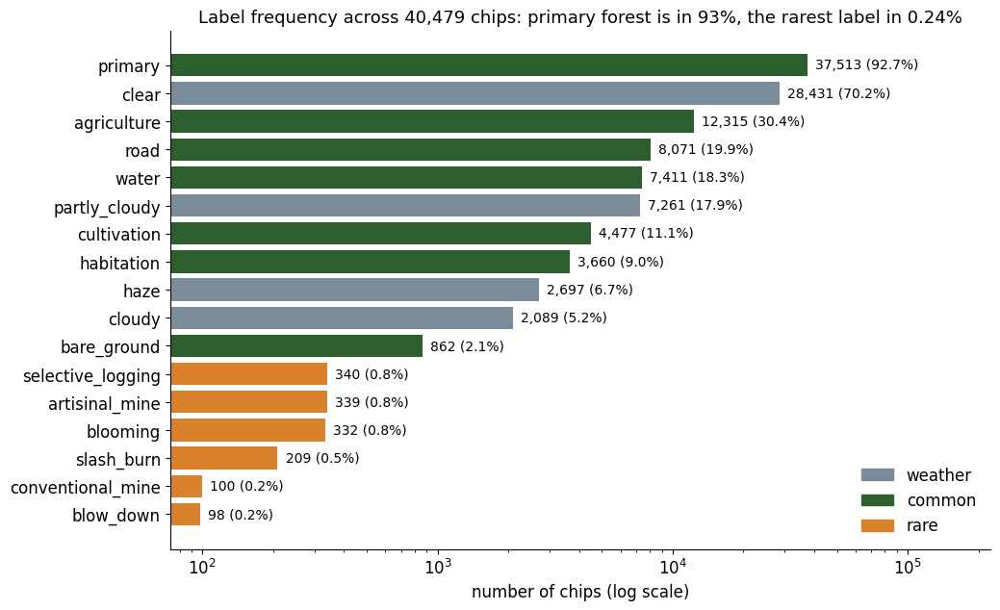

In [ ]:
order = sorted(labels, key=lambda l: freq[L[l]])
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(order, [freq[L[l]] for l in order], color=[GROUP_COLOR[group(l)] for l in order])
ax.set_xscale("log"); ax.set_xlabel("number of chips (log scale)")
for b, l in zip(bars, order):
    ax.text(b.get_width() * 1.08, b.get_y() + b.get_height() / 2, f"{freq[L[l]]:,} ({freq[L[l]] / N:.1%})",
            va="center", fontsize=10)
ax.set_xlim(right=freq.max() * 6)
handles = [mpl.patches.Patch(color=c, label=g) for g, c in GROUP_COLOR.items()]
ax.legend(handles=handles, loc="lower right", frameon=False)
ax.set_title(f"Label frequency across {N:,} chips: primary forest is in {freq[L['primary']] / N:.0%}, "
             f"the rarest label in {freq.min() / N:.2%}" if "primary" in L else "Label frequency")
save(fig, "01_label_frequency.png"); plt.show()

saved deck_01_label_frequency.png


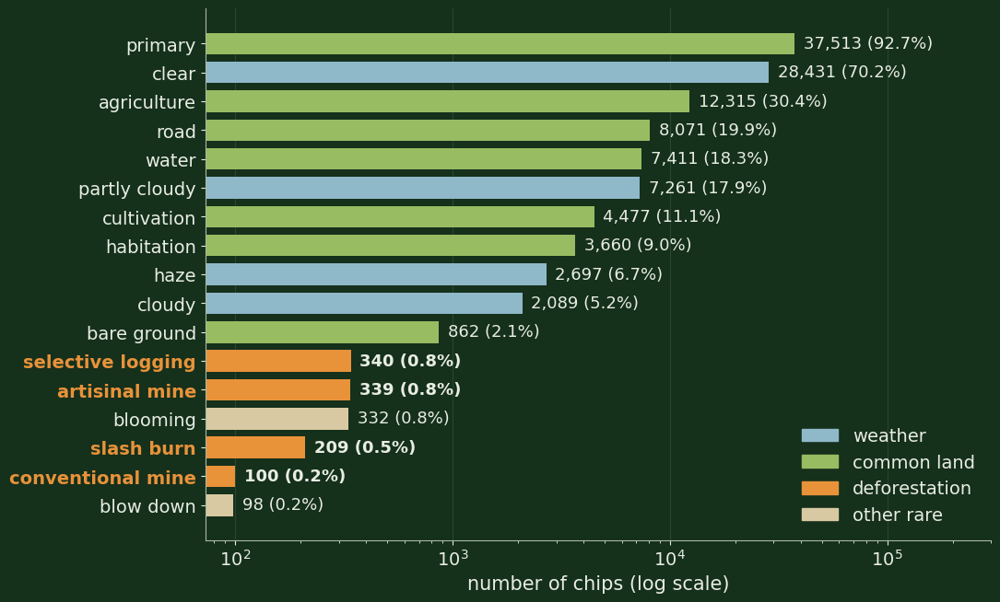

In [ ]:
# Cell 2 of 2: label frequency for slide 3 (add after section 4)
# ===== Slide figure: label frequency, deck style (needs the deck-style cell above)
# Colors: weather = blue-gray, common land = moss green, deforestation = orange, other rare = sand
def deck_group(l):
    if l in WEATHER: return "weather"
    if l in DEFOR_LABELS: return "deforestation"
    if l in RARE: return "other rare"
    return "common land"
DECK_COLOR = {"weather": DECK["sky"], "common land": DECK["moss"], "deforestation": DECK["orange"], "other rare": DECK["sand"]}

order = sorted(labels, key=lambda l: freq[L[l]])
fig, ax = plt.subplots(figsize=(11, 7.5))
bars = ax.barh([l.replace("_", " ") for l in order], [freq[L[l]] for l in order],
               color=[DECK_COLOR[deck_group(l)] for l in order], height=0.75)
ax.set_xscale("log"); ax.set_xlabel("number of chips (log scale)")
ax.set_xlim(right=freq.max() * 8)
for b, l in zip(bars, order):
    ax.text(b.get_width() * 1.1, b.get_y() + b.get_height() / 2, f"{freq[L[l]]:,} ({freq[L[l]] / N:.1%})",
            va="center", fontsize=13, color=DECK["text"],
            fontweight="bold" if l in DEFOR_LABELS else "normal")
for t in ax.get_yticklabels():                      # deforestation labels in orange on the axis too
    if t.get_text().replace(" ", "_") in DEFOR_LABELS:
        t.set_color(DECK["orange"]); t.set_fontweight("bold")
ax.legend(handles=[mpl.patches.Patch(color=c, label=g) for g, c in DECK_COLOR.items()],
          loc="lower right", frameon=False)
ax.grid(axis="x", which="major", alpha=0.5); ax.set_axisbelow(True)
save(fig, "deck_01_label_frequency.png"); plt.show()

## 5. Label co-occurrence
Each cell shows: **of the chips that have the row label, what % also have the column label.** Read across a row. For example, the `cloudy` row is nearly empty, because cloudy chips almost never carry land labels.

saved 02_label_cooccurrence.png


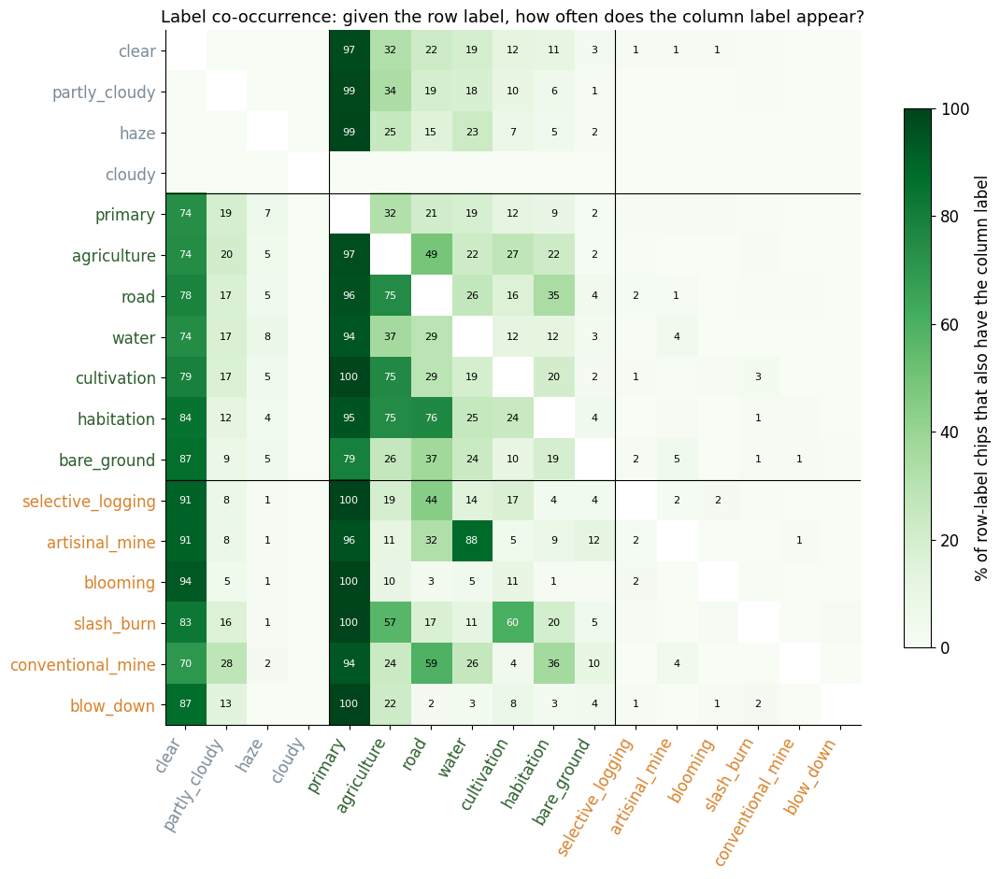

In [ ]:
ordered = WEATHER + sorted(COMMON, key=lambda l: -freq[L[l]]) + sorted(RARE, key=lambda l: -freq[L[l]])
idx = [L[l] for l in ordered]
co = (Y[:, idx].T.astype(np.int64) @ Y[:, idx].astype(np.int64))       # co-occurrence counts
cond = co / np.maximum(np.diag(co)[:, None], 1) * 100                   # P(column | row) in %
np.fill_diagonal(cond, np.nan)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cond, cmap="Greens", vmin=0, vmax=100)
ax.set_xticks(range(len(ordered))); ax.set_xticklabels(ordered, rotation=60, ha="right")
ax.set_yticks(range(len(ordered))); ax.set_yticklabels(ordered)
for t, l in zip(ax.get_xticklabels(), ordered): t.set_color(GROUP_COLOR[group(l)])
for t, l in zip(ax.get_yticklabels(), ordered): t.set_color(GROUP_COLOR[group(l)])
for r in range(len(ordered)):
    for c in range(len(ordered)):
        if r != c and cond[r, c] >= 1:
            ax.text(c, r, f"{cond[r, c]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if cond[r, c] > 60 else "black")
for b in (len(WEATHER) - 0.5, len(WEATHER) + len(COMMON) - 0.5):        # group separators
    ax.axhline(b, color="black", lw=0.8); ax.axvline(b, color="black", lw=0.8)
fig.colorbar(im, ax=ax, shrink=0.75, label="% of row-label chips that also have the column label")
ax.set_title("Label co-occurrence: given the row label, how often does the column label appear?")
save(fig, "02_label_cooccurrence.png"); plt.show()
np.savetxt(os.path.join(OUT, "cooccurrence_counts.csv"), co, fmt="%d", delimiter=",", header=",".join(ordered))

## 6. Labels per chip, weather, and how weather hides land labels

saved 03_labels_per_chip_and_weather.png


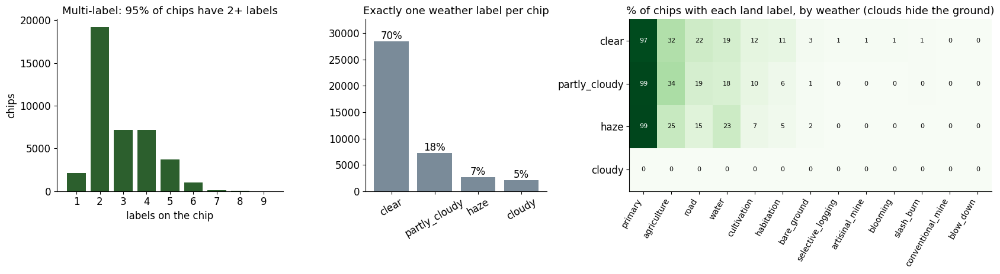

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 0.8, 1.6]})

ks, cnt = np.unique(perChip, return_counts=True)                        # labels per chip
axes[0].bar(ks, cnt, color=GROUP_COLOR["common"])
axes[0].set_xlabel("labels on the chip"); axes[0].set_ylabel("chips"); axes[0].set_xticks(ks)
axes[0].set_title(f"Multi-label: {np.mean(perChip > 1):.0%} of chips have 2+ labels")

wc = [Y[:, L[w]].sum() for w in WEATHER]                                # weather shares
axes[1].bar(WEATHER, wc, color=GROUP_COLOR["weather"])
for x, v in enumerate(wc): axes[1].text(x, v, f"{v / N:.0%}", ha="center", va="bottom")
axes[1].set_ylim(top=max(wc) * 1.15)
axes[1].set_title("Exactly one weather label per chip"); axes[1].tick_params(axis="x", rotation=30)

land = sorted(COMMON, key=lambda l: -freq[L[l]]) + sorted(RARE, key=lambda l: -freq[L[l]])
M = np.array([[Y[Y[:, L[w]] == 1, L[l]].mean() * 100 for l in land] for w in WEATHER])
im = axes[2].imshow(M, cmap="Greens", vmin=0, vmax=100, aspect="auto")
axes[2].set_xticks(range(len(land))); axes[2].set_xticklabels(land, rotation=60, ha="right", fontsize=10)
axes[2].set_yticks(range(len(WEATHER))); axes[2].set_yticklabels(WEATHER)
for r in range(len(WEATHER)):
    for c in range(len(land)):
        axes[2].text(c, r, f"{M[r, c]:.0f}", ha="center", va="center", fontsize=8,
                     color="white" if M[r, c] > 60 else "black")
axes[2].set_title("% of chips with each land label, by weather (clouds hide the ground)")
plt.tight_layout(); save(fig, "03_labels_per_chip_and_weather.png"); plt.show()

## 7. Label counts in each split
The split is stratified by each chip's rarest label, so every label appears in train, validation and test in roughly 70/15/15 proportions. The small test counts for rare labels are why the confidence intervals are wide.

label                  train     val    test
primary               26,259   5,616   5,638
clear                 19,901   4,258   4,272
agriculture            8,583   1,901   1,831
road                   5,656   1,201   1,214
water                  5,201   1,096   1,114
partly_cloudy          5,080   1,094   1,087
cultivation            3,143     663     671
habitation             2,550     556     554
haze                   1,891     406     400
cloudy                 1,462     314     313
bare_ground              607     126     129
selective_logging        237      52      51
artisinal_mine           238      50      51
blooming                 231      50      51
slash_burn               147      31      31
conventional_mine         70      15      15
blow_down                 69      14      15
saved 04_rare_labels_per_split.png


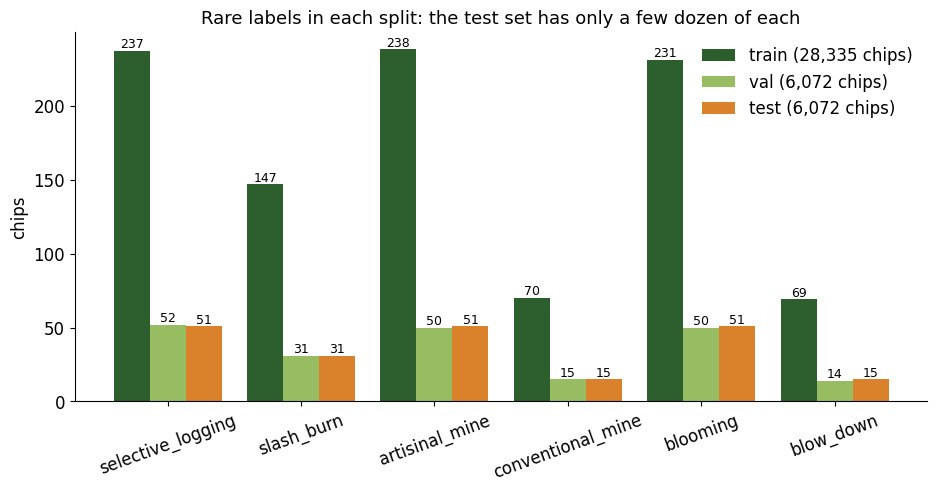

In [ ]:
splitNames = ["train", "val", "test"]
counts = {s: Y[sp[s]].sum(0) for s in splitNames}
print(f"{'label':<20}" + "".join(f"{s:>8}" for s in splitNames))
for l in sorted(labels, key=lambda l: -freq[L[l]]):
    print(f"{l:<20}" + "".join(f"{counts[s][L[l]]:>8,}" for s in splitNames))

fig, ax = plt.subplots(figsize=(11, 4.8))
w = 0.27
x = np.arange(len(RARE))
for k, (s, c) in enumerate(zip(splitNames, ["#2C5F2D", "#97BC62", "#D9822B"])):
    v = [counts[s][L[l]] for l in RARE]
    b = ax.bar(x + (k - 1) * w, v, w, label=f"{s} ({len(sp[s]):,} chips)", color=c)
    for bi, vi in zip(b, v): ax.text(bi.get_x() + w / 2, vi, str(vi), ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(RARE, rotation=20); ax.set_ylabel("chips")
ax.legend(frameon=False); ax.set_title("Rare labels in each split: the test set has only a few dozen of each")
save(fig, "04_rare_labels_per_split.png"); plt.show()

## 8. One example chip per label
Each example is chosen at random among chips with that label, preferring clear weather so the ground is visible. The caption lists all of the chip's tags. Change `SEED` in section 1 to draw different examples.

saved 05_example_chip_per_label.png


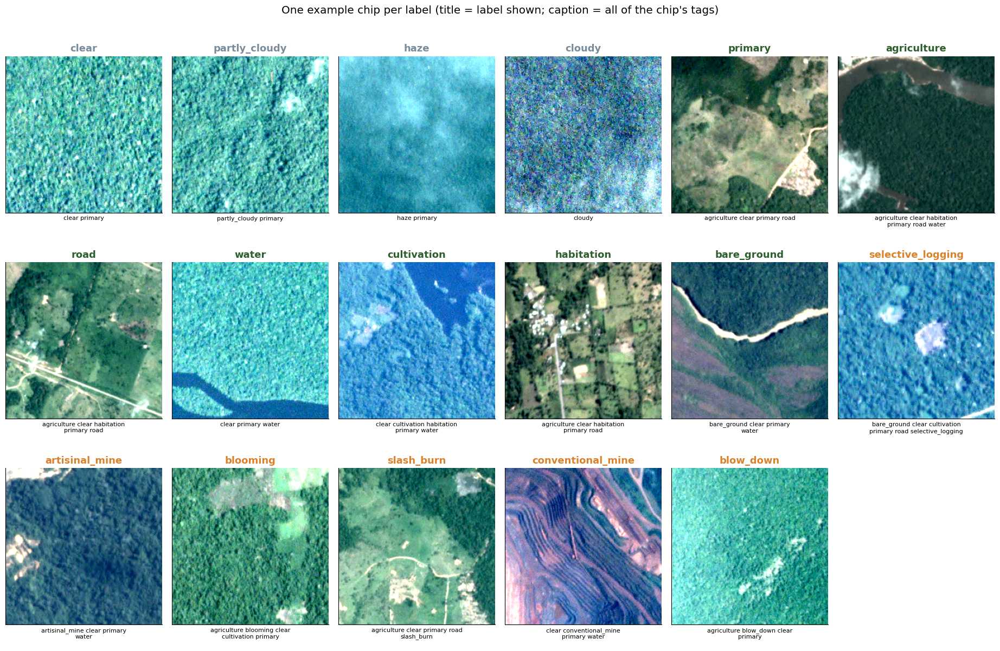

In [ ]:
def pick(l, n=1, prefer_clear=True):
    pos = np.where(Y[:, L[l]] == 1)[0]
    if prefer_clear and l not in WEATHER and "clear" in L:
        clear = pos[Y[pos, L["clear"]] == 1]
        pos = clear if len(clear) >= n else pos
    return rng.choice(pos, min(n, len(pos)), replace=False)

showOrder = WEATHER + sorted(COMMON, key=lambda l: -freq[L[l]]) + sorted(RARE, key=lambda l: -freq[L[l]])
cols = 6
rows = int(np.ceil(len(showOrder) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(3.1 * cols, 4.0 * rows))
for ax, l in zip(axes.flat, showOrder):
    i = pick(l)[0]
    ax.imshow(stretch(rgb(chip(i))))
    ax.set_title(l, color=GROUP_COLOR[group(l)], fontweight="bold")
    ax.set_xlabel("\n".join(textwrap.wrap(tags(i), 30)), fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes.flat[len(showOrder):]: ax.axis("off")
fig.suptitle("One example chip per label (title = label shown; caption = all of the chip's tags)", y=1.0)
plt.tight_layout(); save(fig, "05_example_chip_per_label.png"); plt.show()

## 9. RGB vs. near-infrared vs. NDVI
Healthy vegetation reflects near-infrared strongly and absorbs red light, so NDVI is high (green) over forest and low (red) over cleared land, roads and mines, and negative over water. The NDVI here is computed from raw sensor values, so it's approximate.

saved 06_rgb_nir_ndvi.png


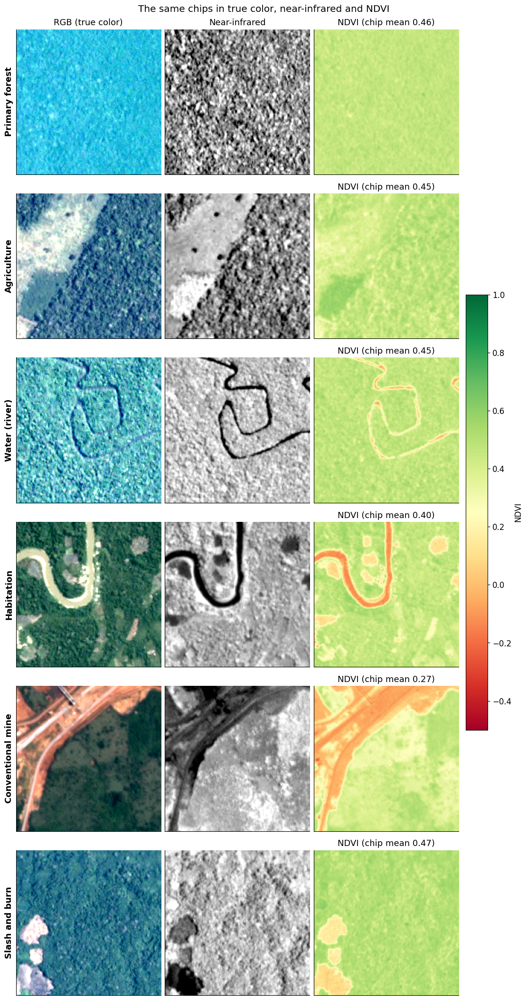

In [ ]:
def pure(l, exclude):
    """Clear chips with label l and none of the labels in `exclude` (cleaner examples)."""
    pos = np.where(Y[:, L[l]] == 1)[0]
    if "clear" in L: pos = pos[Y[pos, L["clear"]] == 1]
    ex = [L[e] for e in exclude if e in L and e != l]
    if ex: pos = pos[Y[np.ix_(pos, ex)].sum(1) == 0]
    return pos

examples = [("primary", "Primary forest", ["agriculture", "road", "habitation", "water", "cultivation"] + RARE),
            ("agriculture", "Agriculture", ["water"] + RARE),
            ("water", "Water (river)", RARE),
            ("habitation", "Habitation", RARE),
            ("conventional_mine", "Conventional mine", []),
            ("slash_burn", "Slash and burn", [])]
examples = [e for e in examples if e[0] in L]
fig, axes = plt.subplots(len(examples), 3, figsize=(11, 3.5 * len(examples)), layout="constrained")
axes = np.atleast_2d(axes)
for r, (l, title, ex) in enumerate(examples):
    pos = pure(l, ex)
    pos = pos if len(pos) else np.where(Y[:, L[l]] == 1)[0]
    x = chip(rng.choice(pos))
    axes[r, 0].imshow(stretch(rgb(x)))
    axes[r, 1].imshow(stretch(x[3]), cmap="gray")
    im = axes[r, 2].imshow(ndvi(x), cmap="RdYlGn", vmin=-0.5, vmax=1.0)
    axes[r, 0].set_ylabel(title, fontsize=13, fontweight="bold")
    heads = ["RGB (true color)", "Near-infrared", "NDVI"] if r == 0 else ["", "", "NDVI"]
    for c in range(3):
        t = heads[c] + (f" (chip mean {ndvi(x).mean():.2f})" if c == 2 else "")
        axes[r, c].set_title(t); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
fig.colorbar(im, ax=axes[:, 2], shrink=0.6, label="NDVI")
fig.suptitle("The same chips in true color, near-infrared and NDVI")
save(fig, "06_rgb_nir_ndvi.png"); plt.show()

## 10. NDVI by label
The average NDVI of every chip, grouped by label. It shows NDVI separates forest from water and cloud, but the rare deforestation labels overlap heavily with forest, because most of each chip is still forest.

saved 07_ndvi_by_label.png


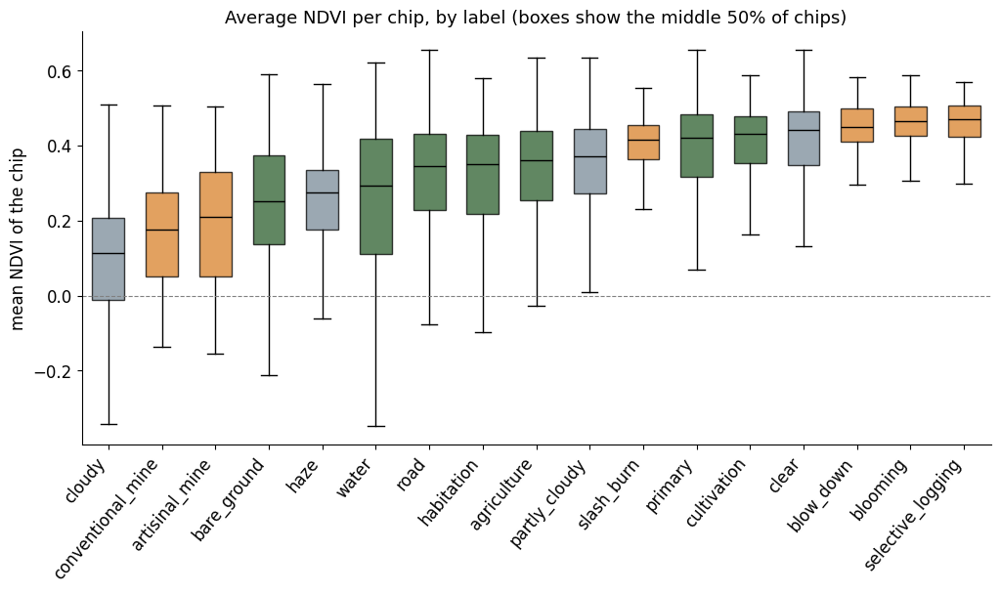

In [ ]:
meanNdvi = np.empty(N, dtype=np.float32)
for s in range(0, N, 2000):                                            # read the NDVI channel in chunks
    meanNdvi[s:s + 2000] = np.asarray(X128[s:s + 2000, 4], dtype=np.float32).mean((1, 2)) * 2 - 1
byLabel = sorted(labels, key=lambda l: np.median(meanNdvi[Y[:, L[l]] == 1]))
fig, ax = plt.subplots(figsize=(12, 5.5))
bp = ax.boxplot([meanNdvi[Y[:, L[l]] == 1] for l in byLabel], showfliers=False, patch_artist=True, widths=0.6)
for patch, l in zip(bp["boxes"], byLabel):
    patch.set_facecolor(GROUP_COLOR[group(l)]); patch.set_alpha(0.75)
for m in bp["medians"]: m.set_color("black")
ax.set_xticks(range(1, len(byLabel) + 1)); ax.set_xticklabels(byLabel, rotation=50, ha="right")
ax.set_ylabel("mean NDVI of the chip"); ax.axhline(0, color="gray", lw=0.8, ls="--")
ax.set_title("Average NDVI per chip, by label (boxes show the middle 50% of chips)")
save(fig, "07_ndvi_by_label.png"); plt.show()

## 11. Original 256 px vs. resized 128 px for the rare labels
For each chip the figure shows the full chip at both resolutions, then a zoom into the 64 × 64 pixel area where resizing removes the most detail (the yellow box). "Detail lost" is the share of the chip's variation that disappears when it is shrunk to 128 px. Rerun with a different `SEED` to see other chips.

saved 08_resolution_rare_labels.png


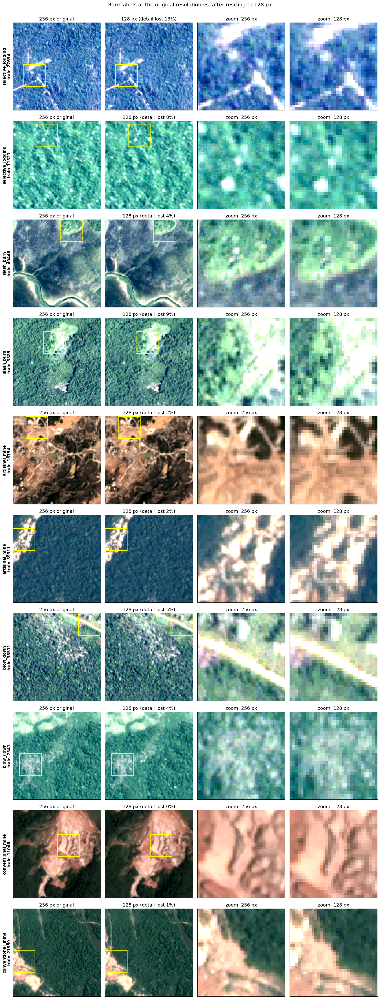

In [ ]:
RES_LABELS = [l for l in ["selective_logging", "slash_burn", "artisinal_mine", "blow_down", "conventional_mine"] if l in L]
PER_LABEL = 2
WIN = 64                                                               # zoom window, in 256 px coordinates

def detail_window(big, small):
    g_big, g_small = big.mean(-1), small.mean(-1)
    up = cv2.resize(g_small, (256, 256), interpolation=cv2.INTER_LINEAR)
    lossMap = (g_big - up) ** 2
    lost = lossMap.sum() / (((g_big - g_big.mean()) ** 2).sum() + 1e-9)
    s = cv2.blur(lossMap, (WIN, WIN))[WIN // 2: 256 - WIN // 2 + 1, WIN // 2: 256 - WIN // 2 + 1]
    y0, x0 = np.unravel_index(np.argmax(s), s.shape)                   # top-left of the lossiest window
    return y0, x0, lost

if not HAS256:
    print("No 256 px cache: skipping this figure. Restore amazon_tif_256 in section 1 to build it.")
else:
    picks = [(l, i) for l in RES_LABELS for i in pick(l, PER_LABEL)]
    fig, axes = plt.subplots(len(picks), 4, figsize=(15, 3.9 * len(picks)))
    axes = np.atleast_2d(axes)
    for r, (l, i) in enumerate(picks):
        big, small = rgb(X256[i]), rgb(X128[i])
        y0, x0, lost = detail_window(big, small)
        bigS, smallS = stretch(big), stretch(small, big)               # same display stretch for both
        axes[r, 0].imshow(bigS); axes[r, 1].imshow(smallS, interpolation="nearest")
        axes[r, 2].imshow(bigS[y0:y0 + WIN, x0:x0 + WIN], interpolation="nearest")
        axes[r, 3].imshow(smallS[y0 // 2:(y0 + WIN) // 2, x0 // 2:(x0 + WIN) // 2], interpolation="nearest")
        for c, scale in ((0, 1), (1, 0.5)):
            axes[r, c].add_patch(mpl.patches.Rectangle((x0 * scale - 0.5, y0 * scale - 0.5), WIN * scale, WIN * scale,
                                                       fill=False, ec="yellow", lw=2))
        axes[r, 0].set_ylabel(f"{l}\n{names[i]}", fontsize=11, fontweight="bold")
        titles = ["256 px original", f"128 px (detail lost {lost:.0%})", "zoom: 256 px", "zoom: 128 px"]
        for c in range(4):
            axes[r, c].set_title(titles[c]); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    fig.suptitle("Rare labels at the original resolution vs. after resizing to 128 px", y=1.0)
    plt.tight_layout(); save(fig, "08_resolution_rare_labels.png"); plt.show()

In [ ]:
import os
for p in ["/content/drive/MyDrive/amazon_caches",
          "/content/drive/MyDrive/amazon_caches/amazon_tif_256/cache",
          "/content/amazon_tif_256/cache"]:
    print(p, "->", os.listdir(p) if os.path.exists(p) else "MISSING")

/content/drive/MyDrive/amazon_caches -> ['amazon_tif_128', 'amazon_tif_256']
/content/drive/MyDrive/amazon_caches/amazon_tif_256/cache -> ['X.npy', 'cache_meta.json', 'splits.npz', 'Y.npy', 'order.json', 'band_stats.json', 'names.json', 'labels.json', 'stats.npz']
/content/amazon_tif_256/cache -> ['splits.npz', 'names.json', 'labels.json', 'band_stats.json', 'stats.npz', 'cache_meta.json', 'order.json', 'Y.npy', 'X.npy']


### A single slide-sized version: `selective_logging` only
One chip, large, for the preprocessing slide.

saved 09_selective_logging_resize.png


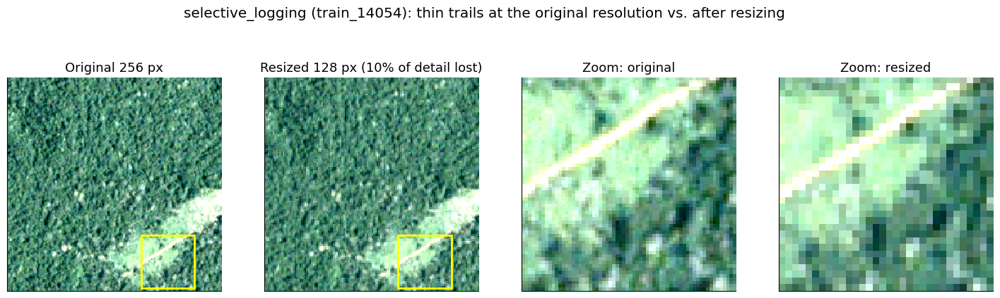

In [ ]:
if HAS256 and "selective_logging" in L:
    i = pick("selective_logging")[0]
    big, small = rgb(X256[i]), rgb(X128[i])
    y0, x0, lost = detail_window(big, small)
    bigS, smallS = stretch(big), stretch(small, big)
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
    panels = [(bigS, "Original 256 px"), (smallS, f"Resized 128 px ({lost:.0%} of detail lost)"),
              (bigS[y0:y0 + WIN, x0:x0 + WIN], "Zoom: original"),
              (smallS[y0 // 2:(y0 + WIN) // 2, x0 // 2:(x0 + WIN) // 2], "Zoom: resized")]
    for ax, (img, t) in zip(axes, panels):
        ax.imshow(img, interpolation="nearest"); ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
    for c, scale in ((0, 1), (1, 0.5)):
        axes[c].add_patch(mpl.patches.Rectangle((x0 * scale - 0.5, y0 * scale - 0.5), WIN * scale, WIN * scale,
                                                fill=False, ec="yellow", lw=2))
    fig.suptitle(f"selective_logging ({names[i]}): thin trails at the original resolution vs. after resizing", y=1.02)
    save(fig, "09_selective_logging_resize.png"); plt.show()

## 12. Copy the figures to Drive

In [ ]:
if os.path.exists("/content/drive/MyDrive"):
    dst = os.path.join(DRIVE_DIR, "eda_figs")
    shutil.copytree(OUT, dst, dirs_exist_ok=True)
    print("copied to", dst)
print(sorted(os.listdir(OUT)))

copied to /content/drive/MyDrive/amazon_caches/eda_figs
['01_label_frequency.png', '02_label_cooccurrence.png', '03_labels_per_chip_and_weather.png', '04_rare_labels_per_split.png', '05_example_chip_per_label.png', '06_rgb_nir_ndvi.png', '07_ndvi_by_label.png', '08_resolution_rare_labels.png', '09_selective_logging_resize.png', 'cooccurrence_counts.csv']


chips with no weather label: [(24448, 'train_24448', 'water')]
train_24448 is in the train split


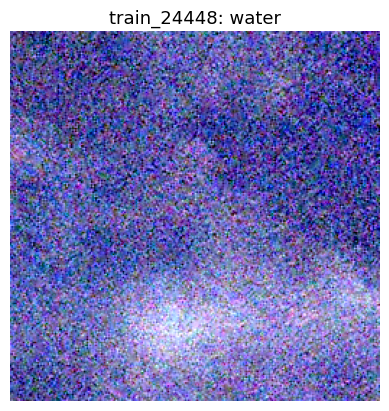

In [ ]:
noWeather = np.where(Y[:, [L[w] for w in WEATHER]].sum(1) == 0)[0]
print("chips with no weather label:", [(int(i), names[i], tags(i)) for i in noWeather])
for i in noWeather:
    split = next(s for s in ["train", "val", "test"] if i in sp[s])
    print(names[i], "is in the", split, "split")
    plt.imshow(stretch(rgb(chip(i)))); plt.title(f"{names[i]}: {tags(i)}"); plt.axis("off"); plt.show()

primary              chip 37025
agriculture          chip 4558
road                 chip 30242
water                chip 3053
selective_logging    chip 31998
slash_burn           chip 27915
artisinal_mine       chip 39311
conventional_mine    chip 17444
saved deck_02_example_chips.png


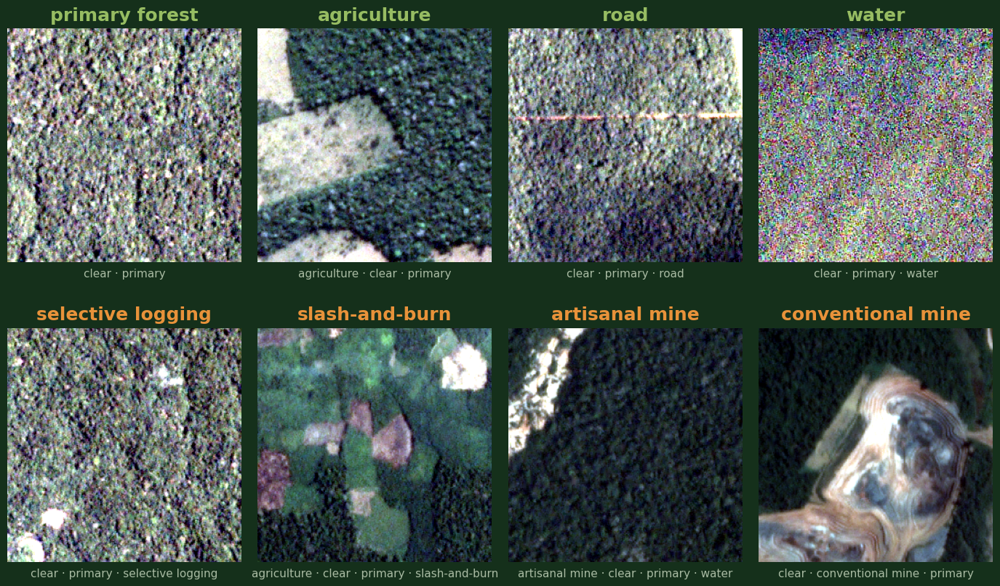

In [ ]:
# ===== Slide figure: 8 example chips (4 common land labels on top, 4 deforestation labels below), deck style
# Needs the deck-style cell and the image helpers from section 2 (chip, tags).
# Each band of each chip is stretched separately (2nd-98th percentile), which removes the
# blue cast and makes the chips look natural. Display only: the cache and the models are unchanged.
COMMON_SHOW = ["primary", "agriculture", "road", "water"]
DEFOR_SHOW  = ["selective_logging", "slash_burn", "artisinal_mine", "conventional_mine"]
PICK = {}          # to choose a chip yourself, set its index here, e.g. PICK = {"water": 1234}
                   # (browse_label("water") in the next cell shows candidates with their indices)

def natural_rgb(x, lo=2, hi=98, gamma=0.9):
    """(5, H, W) chip -> (H, W, 3) image, each band of this chip stretched on its own."""
    img = np.transpose(np.asarray(x[:3], dtype=np.float32), (1, 2, 0))
    out = np.empty_like(img)
    for c in range(3):
        a, b = np.percentile(img[..., c], [lo, hi])
        out[..., c] = np.clip((img[..., c] - a) / (b - a + 1e-6), 0, 1)
    return out ** gamma

def nice_name(l):
    return {"primary": "primary forest", "slash_burn": "slash-and-burn",
            "artisinal_mine": "artisanal mine"}.get(l, l.replace("_", " "))

# Preferred label sets: the example label plus as little else as possible, so it is what stands out
PREFER = {"primary": {"clear", "primary"}, "agriculture": {"agriculture", "clear", "primary"},
          "road": {"clear", "primary", "road"}, "water": {"clear", "primary", "water"}}

def candidates(label):
    """Clear-weather chips with this label, simplest label sets first."""
    has, clear = Y[:, L[label]] == 1, Y[:, L["clear"]] == 1
    if label in PREFER:
        want = np.zeros(len(labels), int); want[[L[l] for l in PREFER[label]]] = 1
        exact = np.where((Y == want).all(1))[0]
        if len(exact): return exact
    cand = np.where(has & clear & (Y.sum(1) <= 4))[0]
    return cand if len(cand) else np.where(has)[0]

def pick_chip(label, seed=7):
    if label in PICK:
        return PICK[label]
    return int(np.random.RandomState(seed).choice(candidates(label)))

fig, axes = plt.subplots(2, 4, figsize=(14, 8.2))
for row, (show, col) in enumerate([(COMMON_SHOW, DECK["moss"]), (DEFOR_SHOW, DECK["orange"])]):
    for ax, l in zip(axes[row], show):
        i = pick_chip(l)
        ax.imshow(natural_rgb(chip(i)))
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.set_title(nice_name(l), color=col, fontsize=18, fontweight="bold", pad=8)
        ax.set_xlabel(" \u00b7 ".join(nice_name(t) if t != "primary" else "primary" for t in tags(i).split()),
                      color=DECK["muted"], fontsize=11, labelpad=6)
        print(f"{l:<20} chip {i}")
fig.tight_layout(h_pad=2.5)
save(fig, "deck_02_example_chips.png"); plt.show()


# ===== Browse candidates for one label (to choose chips for PICK), e.g. browse_label("selective_logging")
def browse_label(label, n=12, seed=0):
    cand = candidates(label)
    show = np.random.RandomState(seed).choice(cand, min(n, len(cand)), replace=False)
    fig, axes = plt.subplots(2, 6, figsize=(16, 6))
    for ax, i in zip(axes.ravel(), show):
        ax.imshow(natural_rgb(chip(i))); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"chip {i}", fontsize=12, color=DECK["text"])
    for ax in axes.ravel()[len(show):]:
        ax.axis("off")
    fig.suptitle(f"{nice_name(label)}: {len(cand)} candidates (change seed= to see others)", color=DECK["text"])
    fig.tight_layout(); plt.show()

saved deck_03_bands.png


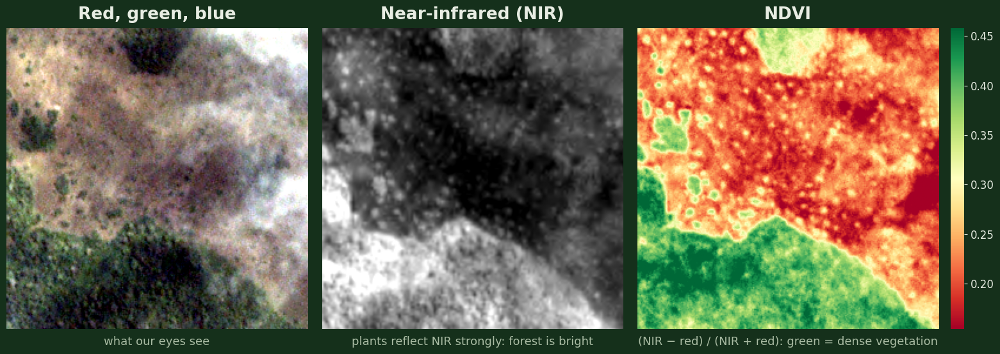

chip 32081: agriculture clear primary water


In [ ]:
# ===== Slide figure: one chip as RGB, near-infrared (NIR) and NDVI, deck style
# Needs the deck-style cell, the image helpers from section 2 (chip, ndvi, tags) and natural_rgb
# from the example-chips cell. Picks a clear chip where forest sits next to water and cleared land,
# so the three views differ clearly.
BAND_CHIP = None          # set a chip index to choose one yourself (browse_bands() shows candidates)

def band_candidates():
    has = lambda l: Y[:, L[l]] == 1
    cleared = has("agriculture") | has("bare_ground")
    return np.where(has("clear") & has("primary") & has("water") & cleared & (Y.sum(1) <= 5))[0]

def nir_view(x, lo=2, hi=98):
    """NIR band, stretched per chip for display: bright = strong NIR reflection (healthy plants)."""
    v = np.asarray(x[3], dtype=np.float32)
    a, b = np.percentile(v, [lo, hi])
    return np.clip((v - a) / (b - a + 1e-6), 0, 1)

def draw_bands(i, fname=None):
    x = chip(i)
    nd = ndvi(x)                                       # back to the real NDVI scale, -1 to 1
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.9))
    axes[0].imshow(natural_rgb(x))
    axes[1].imshow(nir_view(x), cmap="gray")
    lo, hi = np.percentile(nd, [2, 98])                # color range from this chip (display only)
    im = axes[2].imshow(nd, cmap="RdYlGn", vmin=lo, vmax=hi)
    titles = [("Red, green, blue", "what our eyes see"),
              ("Near-infrared (NIR)", "plants reflect NIR strongly: forest is bright"),
              ("NDVI", "(NIR − red) / (NIR + red): green = dense vegetation")]
    for ax, (t, sub) in zip(axes, titles):
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.set_title(t, fontsize=19, fontweight="bold", color=DECK["text"], pad=10)
        ax.set_xlabel(sub, fontsize=13, color=DECK["muted"], labelpad=8)
    fig.tight_layout()
    cax = axes[2].inset_axes([1.04, 0.0, 0.045, 1.0])  # colorbar beside the panel, same panel size as the others
    cb = fig.colorbar(im, cax=cax)
    cb.ax.tick_params(colors=DECK["text"], labelsize=12); cb.outline.set_visible(False)
    if fname:
        save(fig, fname)
    plt.show()
    print(f"chip {i}: {tags(i)}")

def browse_bands(n=6, seed=0):
    """Show candidate chips (RGB only) with their indices, to choose BAND_CHIP."""
    cand = band_candidates()
    show = np.random.RandomState(seed).choice(cand, min(n, len(cand)), replace=False)
    fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3.4))
    for ax, i in zip(np.atleast_1d(axes), show):
        ax.imshow(natural_rgb(chip(i))); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"chip {i}", fontsize=12, color=DECK["text"])
    fig.suptitle(f"{len(cand)} candidates (change seed= to see others)", color=DECK["text"])
    fig.tight_layout(); plt.show()

i_band = BAND_CHIP if BAND_CHIP is not None else int(np.random.RandomState(3).choice(band_candidates()))
draw_bands(i_band, "deck_03_bands.png")

saved deck_04_oversampling.png


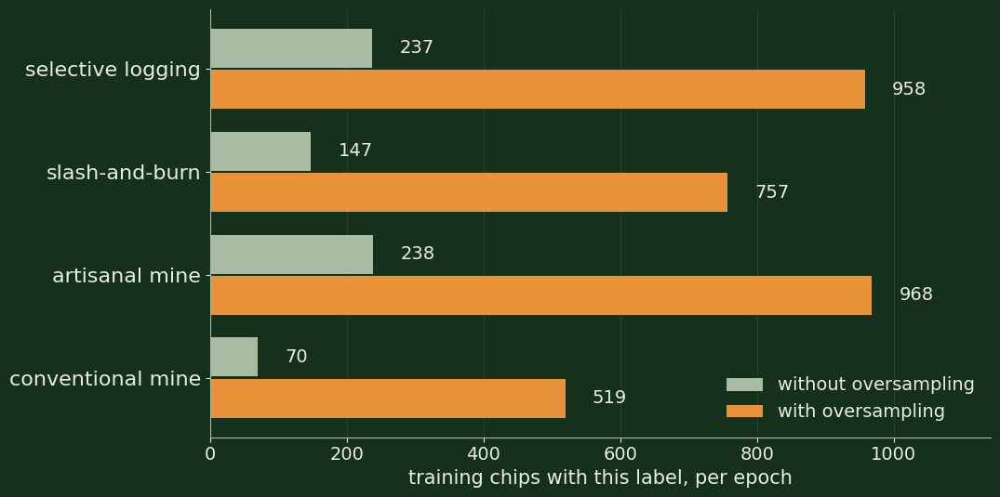

pos_weight: {'selective_logging': 10.0, 'slash_burn': 10.0, 'artisinal_mine': 10.0, 'conventional_mine': 10.0}
times as likely to be drawn as a plain clear-forest chip: {'selective_logging': 9.2, 'slash_burn': 11.6, 'artisinal_mine': 9.1, 'conventional_mine': 16.9}
seen per epoch, without -> with: {'selective_logging': '237 -> 958', 'slash_burn': '147 -> 757', 'artisinal_mine': '238 -> 968', 'conventional_mine': '70 -> 519'}


In [ ]:
# ===== Slide figure: how often each deforestation label is seen per epoch, without vs. with oversampling
# Uses the same formulas as run_ladder.py:
#   pos_weight (loss)   = sqrt((1 - f) / f), clipped to [1, 10]   (f = label frequency in training chips)
#   sampling weight     = for each chip, the largest f ** -0.5 over its labels (its rarest label decides)
# Needs the deck-style cell and the splits (sp) and labels (Y, L) from the setup cells.
tr = sp["train"]
ytr = Y[tr].astype(float)
f = ytr.mean(0).clip(1e-6, None)
w = (ytr * f ** -0.5).max(1)                          # one sampling weight per training chip
p = w / w.sum()
seen_with = len(tr) * (ytr * p[:, None]).sum(0)       # expected chips with each label, per epoch
seen_without = ytr.sum(0)                             # without oversampling: each chip once per epoch
pos_w = np.clip(np.sqrt((1 - f) / f), 1, 10)

show = DEFOR_LABELS
names = [{"slash_burn": "slash-and-burn", "artisinal_mine": "artisanal mine"}.get(l, l.replace("_", " ")) for l in show]
yy = np.arange(len(show))[::-1]
fig, ax = plt.subplots(figsize=(11, 5.6))
b0 = ax.barh(yy + 0.2, [seen_without[L[l]] for l in show], 0.38, color=DECK["muted"], label="without oversampling")
b1 = ax.barh(yy - 0.2, [seen_with[L[l]] for l in show], 0.38, color=DECK["orange"], label="with oversampling")
for bars in (b0, b1):
    for b in bars:
        ax.text(b.get_width() + 40, b.get_y() + b.get_height() / 2, f"{b.get_width():,.0f}",
                va="center", fontsize=14, color=DECK["text"])
ax.set_yticks(yy); ax.set_yticklabels(names, fontsize=16)
ax.set_xlabel("training chips with this label, per epoch")
ax.set_xlim(right=max(seen_with[L[l]] for l in show) * 1.18)
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="x", alpha=0.4); ax.set_axisbelow(True)
fig.tight_layout()
save(fig, "deck_04_oversampling.png"); plt.show()

# Numbers for the slide
plain = np.where((Y[tr][:, L["primary"]] == 1) & (Y[tr][:, L["clear"]] == 1) & (Y[tr].sum(1) == 2))[0]
print("pos_weight:", {l: round(float(pos_w[L[l]]), 1) for l in show})
print("times as likely to be drawn as a plain clear-forest chip:",
      {l: round(float(f[L[l]] ** -0.5 / w[plain].mean()), 1) for l in show})
print("seen per epoch, without -> with:", {l: f"{seen_without[L[l]]:.0f} -> {seen_with[L[l]]:.0f}" for l in show})